In [26]:
import geopandas as gpd
import pandas as pd
import re
import numpy as np
# Load data
retail_landuse_h3 = gpd.read_parquet("../data/input_files/retail_landuse_h3_geo.parquet")
retail_landuse = gpd.read_parquet("../data/input_files/retail_landuse.parquet")
foursquare_pois = gpd.read_parquet("../data/input_files/uk_foursquare_cc_aug_retailfilt_geo.parquet")
retail_park_stores = pd.read_csv("../data/input_files/bl_retail_parks_brands_deduped.csv")



#keep only rows where "classic?" is yes
retail_park_stores = retail_park_stores[retail_park_stores["classic"] == "yes"].copy()


# --- Regex-based whole-word filtering ---

# Helper: turn a brand into a whole-word regex (case-insensitive, flexible whitespace)
def brand_to_pattern(brand: str) -> str:
    brand = str(brand).strip().lower()
    tokens = re.split(r"\s+", brand)
    return r"\b" + r"\s+".join(re.escape(t) for t in tokens if t) + r"\b"

# Build a single alternation regex for all brands
brands = retail_park_stores["brand"].dropna().astype(str).str.strip().str.lower().unique()
brand_patterns = [brand_to_pattern(b) for b in brands if b]
big_pattern = r"(?i)(" + "|".join(brand_patterns) + r")"  # (?i) = case-insensitive

# Apply to Foursquare names
name_series = foursquare_pois["name"].astype(str)
mask = name_series.str.contains(big_pattern, regex=True, na=False)

# Filtered POIs: only those where a full brand word/phrase occurs
foursquare_pois_filtered = foursquare_pois[mask].copy()
foursquare_pois_filtered["matched_brand_text"] = name_series[mask].str.extract(big_pattern, expand=False)

# --- Count matches per brand ---

# Normalize matched text for grouping
foursquare_pois_filtered["matched_brand_norm"] = (
    foursquare_pois_filtered["matched_brand_text"].str.lower().str.strip()
)

# Count how many times each brand occurs
brand_counts = (
    foursquare_pois_filtered["matched_brand_norm"]
    .value_counts()
    .rename_axis("brand_norm")
    .reset_index(name="match_count")
)

# Merge back into retail_park_stores
retail_park_stores["brand_norm"] = retail_park_stores["brand"].str.lower().str.strip()
retail_park_stores_with_counts = retail_park_stores.merge(
    brand_counts, on="brand_norm", how="left"
)

# Fill NaN with 0 (no matches found) and sort
retail_park_stores_with_counts["match_count"] = (
    retail_park_stores_with_counts["match_count"].fillna(0).astype(int)
)
retail_park_stores_with_counts_sorted = (
    retail_park_stores_with_counts
    .sort_values("match_count", ascending=False)
    .reset_index(drop=True)
)


/tmp/ipykernel_1198/3844338576.py:32: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask = name_series.str.contains(big_pattern, regex=True, na=False)


In [27]:
foursquare_pois_filtered

,fsq_place_id,name,lat,lng,address,locality,region,postcode,admin_region,post_town,...,date_refreshed,date_closed,tel,website,fsq_category_id,fsq_category_labels,h3_11,geometry,matched_brand_text,matched_brand_norm
94,4c8a3cff1eafb1f74e4a7835,Furniture Village,51.483930,0.273460,"The Junction, Thurrock Retail Park",Thurrock,Thurrock,RM20 3LP,England,None,...,2025-01-03,None,01708 899421,https://www.furniturevillage.co.uk,4bf58dd8d48988d1f8941735,[Retail > Furniture and Home Store],8b194e6ecd25fff,POINT (0.27346 51.48393),Furniture Village,furniture village
163,5aa3f6e918d43b25d5dabeec,Home Bargains,50.757168,-1.925692,Ringwood Rd,Bournemouth,Dorset,BH11 8LL,England,None,...,2025-07-25,None,01202 581882,https://home.bargains,52dea92d3cf9994f4e043dbb,[Retail > Discount Store],8b195944b10dfff,POINT (-1.92569 50.75717),Home Bargains,home bargains
323,513b4383e4b02357dcc3b221,Dunelm,51.487864,0.271225,West Thurrock Way,West Thurrock,Essex,RM20 3LP,England,None,...,2025-07-02,None,01708 203540,http://www.dunelm.com/stores/thurrock,4bf58dd8d48988d1f8941735,[Retail > Furniture and Home Store],8b194e6e1b4cfff,POINT (0.27122 51.48786),Dunelm,dunelm
869,61cadfadf25747373969f543,Tapi Carpets & Floors,52.074050,-1.343221,6 Lockheed Close,Banbury,Oxfordshire,OX16 1LX,England,None,...,2025-06-05,None,01295 239960,https://www.tapi.co.uk,52f2ab2ebcbc57f1066b8b2a,[Retail > Furniture and Home Store > Carpet St...,8b195dcd6356fff,POINT (-1.34322 52.07405),Tapi Carpets,tapi carpets
886,575ab705498e367168385b3b,Home Bargains,55.609649,-4.496051,21 Kings St,Kilmarnock,East Ayrshire,KA1 1LT,Scotland,None,...,2025-04-24,None,01563 549846,https://home.bargains,52dea92d3cf9994f4e043dbb,[Retail > Discount Store],8b1909255b4bfff,POINT (-4.49605 55.60965),Home Bargains,home bargains
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1491959,0fc05902ecc4483892f5066f,Smyths Toys,50.925850,-1.312280,Tollbar Way Unit 1,Hedge End,Hampshire,SO30 2QY,England,Southampton,...,2024-07-11,None,None,https://www.smythstoys.com,4bf58dd8d48988d1f3941735,[Retail > Toy Store],8b1959170455fff,POINT (-1.31228 50.92585),Smyths Toys,smyths toys
1491969,3ecb2efb32b543e9b462e5d5,Smyths Toys,57.149093,-2.082007,Links Rd Unit 6-7,Aberdeenshire,Aberdeenshire,AB11 5EJ,Scotland,Aberdeen,...,2025-03-08,None,0121 476 7008,https://www.smythstoys.com,4bf58dd8d48988d1f3941735,[Retail > Toy Store],8b1976bb6216fff,POINT (-2.08201 57.14909),Smyths Toys,smyths toys
1491983,65a588d8379b2d2bdd3e6b3a,DFS Outlet Store - Thurrock,51.485279,0.276209,None,Grays Thurrock,Essex,RM20 1WN,None,None,...,2025-07-28,None,0333 999 9777,https://www.dfs.co.uk,4bf58dd8d48988d1f8941735,"[Retail > Furniture and Home Store, Retail > O...",8b194e65261afff,POINT (0.27621 51.48528),DFS,dfs
1492144,4fae0bfbe4b085f6b27efd5e,Halfords,50.840898,-1.042474,Jackson Close,Farlington,Hampshire,None,England,None,...,2023-06-20,None,023 9232 5066,http://www.halfords.com,63be6904847c3692a84b9be6,[Business and Professional Services > Automoti...,8b1959b8e60dfff,POINT (-1.04247 50.8409),Halfords,halfords


In [28]:
#looks decent but "Mango" getting some extras (this is a clothing outlet) 
#I could mannually get the cat(s) for each of the brands and further filter with that
foursquare_pois_filtered

,fsq_place_id,name,lat,lng,address,locality,region,postcode,admin_region,post_town,...,date_refreshed,date_closed,tel,website,fsq_category_id,fsq_category_labels,h3_11,geometry,matched_brand_text,matched_brand_norm
94,4c8a3cff1eafb1f74e4a7835,Furniture Village,51.483930,0.273460,"The Junction, Thurrock Retail Park",Thurrock,Thurrock,RM20 3LP,England,None,...,2025-01-03,None,01708 899421,https://www.furniturevillage.co.uk,4bf58dd8d48988d1f8941735,[Retail > Furniture and Home Store],8b194e6ecd25fff,POINT (0.27346 51.48393),Furniture Village,furniture village
163,5aa3f6e918d43b25d5dabeec,Home Bargains,50.757168,-1.925692,Ringwood Rd,Bournemouth,Dorset,BH11 8LL,England,None,...,2025-07-25,None,01202 581882,https://home.bargains,52dea92d3cf9994f4e043dbb,[Retail > Discount Store],8b195944b10dfff,POINT (-1.92569 50.75717),Home Bargains,home bargains
323,513b4383e4b02357dcc3b221,Dunelm,51.487864,0.271225,West Thurrock Way,West Thurrock,Essex,RM20 3LP,England,None,...,2025-07-02,None,01708 203540,http://www.dunelm.com/stores/thurrock,4bf58dd8d48988d1f8941735,[Retail > Furniture and Home Store],8b194e6e1b4cfff,POINT (0.27122 51.48786),Dunelm,dunelm
869,61cadfadf25747373969f543,Tapi Carpets & Floors,52.074050,-1.343221,6 Lockheed Close,Banbury,Oxfordshire,OX16 1LX,England,None,...,2025-06-05,None,01295 239960,https://www.tapi.co.uk,52f2ab2ebcbc57f1066b8b2a,[Retail > Furniture and Home Store > Carpet St...,8b195dcd6356fff,POINT (-1.34322 52.07405),Tapi Carpets,tapi carpets
886,575ab705498e367168385b3b,Home Bargains,55.609649,-4.496051,21 Kings St,Kilmarnock,East Ayrshire,KA1 1LT,Scotland,None,...,2025-04-24,None,01563 549846,https://home.bargains,52dea92d3cf9994f4e043dbb,[Retail > Discount Store],8b1909255b4bfff,POINT (-4.49605 55.60965),Home Bargains,home bargains
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1491959,0fc05902ecc4483892f5066f,Smyths Toys,50.925850,-1.312280,Tollbar Way Unit 1,Hedge End,Hampshire,SO30 2QY,England,Southampton,...,2024-07-11,None,None,https://www.smythstoys.com,4bf58dd8d48988d1f3941735,[Retail > Toy Store],8b1959170455fff,POINT (-1.31228 50.92585),Smyths Toys,smyths toys
1491969,3ecb2efb32b543e9b462e5d5,Smyths Toys,57.149093,-2.082007,Links Rd Unit 6-7,Aberdeenshire,Aberdeenshire,AB11 5EJ,Scotland,Aberdeen,...,2025-03-08,None,0121 476 7008,https://www.smythstoys.com,4bf58dd8d48988d1f3941735,[Retail > Toy Store],8b1976bb6216fff,POINT (-2.08201 57.14909),Smyths Toys,smyths toys
1491983,65a588d8379b2d2bdd3e6b3a,DFS Outlet Store - Thurrock,51.485279,0.276209,None,Grays Thurrock,Essex,RM20 1WN,None,None,...,2025-07-28,None,0333 999 9777,https://www.dfs.co.uk,4bf58dd8d48988d1f8941735,"[Retail > Furniture and Home Store, Retail > O...",8b194e65261afff,POINT (0.27621 51.48528),DFS,dfs
1492144,4fae0bfbe4b085f6b27efd5e,Halfords,50.840898,-1.042474,Jackson Close,Farlington,Hampshire,None,England,None,...,2023-06-20,None,023 9232 5066,http://www.halfords.com,63be6904847c3692a84b9be6,[Business and Professional Services > Automoti...,8b1959b8e60dfff,POINT (-1.04247 50.8409),Halfords,halfords


In [29]:
retail_park_stores_with_counts_sorted


,brand,Cat,highstreet,remove?,classic,notes,brand_norm,match_count
0,B&M,retail,yes,NaN,yes,maybe a distninction between home stores and n...,b&m,826
1,Dreams,retail,no,NaN,yes,NaN,dreams,640
2,Home Bargains,retail,yes,NaN,yes,NaN,home bargains,632
3,Halfords,retail,no,NaN,yes,NaN,halfords,552
4,Pets at Home,retail,no,NaN,yes,NaN,pets at home,544
5,Currys,retail,no,NaN,yes,NaN,currys,481
6,Bensons for Beds,retail,no,NaN,yes,NaN,bensons for beds,329
7,B&Q,retail,no,NaN,yes,(normally on there own_,b&q,325
8,Matalan,retail,no,NaN,yes,NaN,matalan,289
9,Wickes,retail,no,NaN,yes,NaN,wickes,288


In [30]:
# --- Imports ---
import geopandas as gpd
import numpy as np
import pandas as pd

# --- Inputs you already have ---
# retail_landuse: GeoDataFrame of polygons (retail centres)
# foursquare_pois_filtered: GeoDataFrame of points used for matching/brands
# foursquare_pois: GeoDataFrame of ALL Foursquare POIs (unfiltered)

# --- Configurable knobs ---
predicate = "within"      # or "intersects"
poi_col = "name_left"     # or "matched_brand_norm" / "matched_brand_text"

# 1) Ensure both layers share a CRS (use POI CRS as authority)
if retail_landuse.crs is None and foursquare_pois_filtered.crs is not None:
    retail_landuse = retail_landuse.set_crs(foursquare_pois_filtered.crs, allow_override=True)
retail_landuse = retail_landuse.to_crs(foursquare_pois_filtered.crs)

if foursquare_pois.crs != retail_landuse.crs:
    foursquare_pois = foursquare_pois.to_crs(retail_landuse.crs)

# 2) Spatial join: FILTERED POIs within/intersecting polygons (for brand/name counts)
joined = gpd.sjoin(
    foursquare_pois_filtered,
    retail_landuse,
    how="inner",
    predicate=predicate
)

# --- choose the POI name/brand column ---
if poi_col not in joined.columns:
    raise KeyError(
        f"Column '{poi_col}' not found in joined data. "
        f"Available columns: {list(joined.columns)}"
    )

# Optional: normalize empty names
joined[poi_col] = joined[poi_col].fillna("(unknown)")

# 3) Count matched (filtered) POIs per polygon index
matched_counts = joined.groupby("index_right").size()

# 4) Build ordered list of "POI (count)" per polygon from FILTERED set
poi_lists = (
    joined.groupby(["index_right", poi_col])
          .size()
          .reset_index(name="count")
          .sort_values(["index_right", "count", poi_col], ascending=[True, False, True])
          .groupby("index_right")
          .apply(lambda df: [f"{row[poi_col]} ({row['count']})" for _, row in df.iterrows()])
)

# 5) Map matched counts and lists back to polygons
retail_landuse["matched_poi_count"] = (
    retail_landuse.index.to_series().map(matched_counts).fillna(0).astype(int)
)
retail_landuse["matched_poi_list"] = (
    retail_landuse.index.to_series().map(poi_lists).apply(lambda x: x if isinstance(x, list) else [])
)

# 5b) Centre-wide totals from the FULL (unfiltered) Foursquare set
joined_all = gpd.sjoin(
    foursquare_pois,      # FULL set
    retail_landuse,
    how="inner",
    predicate=predicate
)

centre_totals = joined_all.groupby("index_right").size().astype(int)

# Add centre total and ratio columns
retail_landuse["centre_poi_total"] = (
    retail_landuse.index.to_series().map(centre_totals).fillna(0).astype(int)
)

# Ratio of matched (filtered) to centre total (full)
retail_landuse["matched_to_centre_ratio"] = np.where(
    retail_landuse["centre_poi_total"] > 0,
    retail_landuse["matched_poi_count"] / retail_landuse["centre_poi_total"],
    0.0
)

# --- 5c) Polygon areas and "area per POI" metrics ---------------------------------
# Use a suitable projected CRS for area (meters). UTM is a good default.
try:
    area_crs = retail_landuse.estimate_utm_crs()
except Exception:
    area_crs = None

if area_crs is None:
    # Fallback: use Web Mercator if UTM estimation fails (area will be approximate).
    area_crs = "EPSG:3857"

# Compute areas in square meters using the projected CRS
retail_landuse_area = retail_landuse.to_crs(area_crs)
area_sqm = retail_landuse_area.geometry.area

# Add area columns
retail_landuse["area_sqm"] = area_sqm
retail_landuse["area_sqkm"] = retail_landuse["area_sqm"] / 1_000_000.0

# Area per FILTERED matched POI (only defined when matched_poi_count > 0)
retail_landuse["area_per_matched_poi_sqm"] = np.where(
    retail_landuse["matched_poi_count"] > 0,
    retail_landuse["area_sqm"] / retail_landuse["matched_poi_count"],
    np.nan
)
retail_landuse["area_per_matched_poi_sqkm"] = retail_landuse["area_per_matched_poi_sqm"] / 1_000_000.0

# Area per TOTAL centre POI (defined when centre_poi_total > 0)
retail_landuse["area_per_total_poi_sqm"] = np.where(
    retail_landuse["centre_poi_total"] > 0,
    retail_landuse["area_sqm"] / retail_landuse["centre_poi_total"],
    np.nan
)
retail_landuse["area_per_total_poi_sqkm"] = retail_landuse["area_per_total_poi_sqm"] / 1_000_000.0



# 6) Sort polygons by matched count and keep those with ≥1 matched POI
retail_landuse = (
    retail_landuse.sort_values("matched_poi_count", ascending=False)
                  .reset_index(drop=True)
)
retail_landuse = retail_landuse[retail_landuse["matched_poi_count"] >= 1]

cols_front = [
    "matched_poi_count",
    "centre_poi_total",
    "matched_to_centre_ratio",
    "matched_poi_list",
    "area_sqm",
    "area_per_matched_poi_sqm",
    "area_per_total_poi_sqm",
]

other_cols = [c for c in retail_landuse.columns if c not in cols_front + ["geometry"]]
retail_landuse = retail_landuse[cols_front + other_cols + ["geometry"]]

# Result columns:
# - matched_poi_count: number of FILTERED POIs matched in each centre
# - centre_poi_total: number of ALL foursquare_pois in each centre
# - matched_to_centre_ratio: matched_poi_count / centre_poi_total
# - matched_poi_list: ordered "POI (count)" list from the FILTERED set


/tmp/ipykernel_1198/2606652729.py:51: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda df: [f"{row[poi_col]} ({row['count']})" for _, row in df.iterrows()])


In [31]:
import geopandas as gpd
import pandas as pd
import numpy as np

predicate = "within"  # or "intersects"

# --- Required columns check ---
for df_name, df in {
    "foursquare_pois": locals().get("foursquare_pois"),
    "foursquare_pois_filtered": locals().get("foursquare_pois_filtered"),
}.items():
    if df is None:
        raise ValueError(f"{df_name} is not defined.")
    if "fsq_place_id" not in df.columns:
        raise KeyError(f"{df_name} must contain 'fsq_place_id'.")

# --- CRS alignment (trust full POIs CRS) ---
if retail_landuse.crs is None and foursquare_pois.crs is not None:
    retail_landuse = retail_landuse.set_crs(foursquare_pois.crs, allow_override=True)
if retail_landuse.crs != foursquare_pois.crs:
    retail_landuse = retail_landuse.to_crs(foursquare_pois.crs)
if foursquare_pois_filtered.crs != foursquare_pois.crs:
    foursquare_pois_filtered = foursquare_pois_filtered.to_crs(foursquare_pois.crs)

# --- Spatial joins: ALL vs FILTERED ---
joined_all = gpd.sjoin(
    foursquare_pois,
    retail_landuse,
    how="inner",
    predicate=predicate
)
joined_flt = gpd.sjoin(
    foursquare_pois_filtered,
    retail_landuse,
    how="inner",
    predicate=predicate
)

# --- Pick a display name column for reporting ---
def pick_display_name(df):
    for c in ["matched_brand_text", "matched_brand_norm", "name_left", "name", "brand", "poi_name"]:
        if c in df.columns:
            return c
    # Fallback: just show the ID if no name columns exist
    return "fsq_place_id"

name_col_all = pick_display_name(joined_all)

# --- Centre ratios from joins ---
filtered_counts = joined_flt.groupby("index_right").size()
full_counts     = joined_all.groupby("index_right").size()

centre_stats = (
    pd.DataFrame({"matched_poi_count": filtered_counts, "centre_poi_total": full_counts})
      .fillna(0).astype(int)
)
centre_stats["matched_to_centre_ratio"] = np.where(
    centre_stats["centre_poi_total"] > 0,
    centre_stats["matched_poi_count"] / centre_stats["centre_poi_total"],
    0.0
)

# --- Qualifying centres: 0.5 < ratio < 1 (partially matched) ---
qual_centres = centre_stats.index[
    (centre_stats["matched_to_centre_ratio"] > 0.2) &
    (centre_stats["matched_to_centre_ratio"] < 1)
]

if len(qual_centres) == 0:
    unmatched_ranked = pd.DataFrame(columns=["poi_name", "occurrences", "centres_appeared_in"])
else:
    # Restrict to those centres
    ja = joined_all.loc[joined_all["index_right"].isin(qual_centres),
                        ["index_right", "fsq_place_id", name_col_all]].copy()
    jf = joined_flt.loc[joined_flt["index_right"].isin(qual_centres),
                        ["index_right", "fsq_place_id"]].copy()

    # --- Anti-join by fsq_place_id (true unmatched) ---
    matched_ids = set(jf["fsq_place_id"].unique())
    unmatched = ja[~ja["fsq_place_id"].isin(matched_ids)].copy()

    # --- Build ranked table of unmatched names ---
    # Clean name for display
    if name_col_all != "fsq_place_id":
        unmatched["poi_name"] = (
            unmatched[name_col_all]
            .astype(str).str.strip()
            .replace({"": np.nan})
            .fillna(unmatched["fsq_place_id"])
        )
    else:
        unmatched["poi_name"] = unmatched["fsq_place_id"]

    # Count occurrences (per POI record) and in how many centres they appear
    unmatched_ranked = (
        unmatched.groupby("poi_name")
                 .agg(occurrences=("fsq_place_id", "count"),
                      centres_appeared_in=("index_right", "nunique"))
                 .reset_index()
                 .sort_values(["occurrences", "centres_appeared_in", "poi_name"],
                              ascending=[False, False, True])
                 .reset_index(drop=True)
    )

# ---> Result:
# 'unmatched_ranked' = ranked names of POIs present in the original foursquare_pois
# within centres (0.5 < ratio < 1) whose fsq_place_id does NOT appear in the filtered set.
# Columns: poi_name, occurrences, centres_appeared_in

print(unmatched_ranked.head(25))


          poi_name  occurrences  centres_appeared_in
0     Costa Coffee          175                  165
1            Argos          119                  111
2       McDonald's          110                  110
3      Carpetright           94                   92
4    Vets for Pets           90                   88
5             Aldi           89                   86
6              KFC           83                   75
7          TK Maxx           74                   73
8             Next           67                   63
9            Boots           64                   64
10            Lidl           64                   64
11       Starbucks           64                   62
12  We Buy Any Car           61                   58
13         Iceland           59                   59
14   Sports Direct           58                   58
15       Poundland           55                   55
16          Greggs           54                   54
17     Burger King           52               

In [32]:
retail_landuse

,matched_poi_count,centre_poi_total,matched_to_centre_ratio,matched_poi_list,area_sqm,area_per_matched_poi_sqm,area_per_total_poi_sqm,landuse,name,area_sqkm,area_per_matched_poi_sqkm,area_per_total_poi_sqkm,geometry
0,15,67,0.223881,"[Currys (2), B&M Store (1), B&Q (1), Bensons f...",307150.292354,20476.686157,4584.332722,retail,Clifton Moor,0.307150,0.020477,0.004584,"POLYGON ((-1.09844 53.992, -1.09813 53.99147, ..."
1,15,47,0.319149,"[ScS (2), B&M Bargains (1), B&M Home Store (1)...",152266.030828,10151.068722,3239.702784,retail,Solihull Retail Park,0.152266,0.010151,0.003240,"POLYGON ((-1.81813 52.39869, -1.81905 52.39888..."
2,15,67,0.223881,"[Pets at Home (2), B&Q (1), Bensons for Beds S...",222691.114335,14846.074289,3323.747975,retail,Bourne Retail Park,0.222691,0.014846,0.003324,"POLYGON ((-1.78167 51.06512, -1.78096 51.06517..."
3,15,43,0.348837,"[ScS (2), B&M Store (1), Bensons for Beds Thur...",134537.675880,8969.178392,3128.783160,retail,Lakeside Retail Park,0.134538,0.008969,0.003129,"POLYGON ((0.27875 51.48417, 0.2773 51.48434, 0..."
4,15,89,0.168539,"[ScS (2), Bensons for Beds (1), Bensons for Be...",205257.680869,13683.845391,2306.266077,retail,Middlebrook,0.205258,0.013684,0.002306,"POLYGON ((-2.53395 53.58106, -2.53443 53.58133..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1988,1,248,0.004032,[Currys (1)],117866.417591,117866.417591,475.267813,retail,None,0.117866,0.117866,0.000475,"POLYGON ((-1.30758 52.97379, -1.30756 52.97372..."
1989,1,7,0.142857,[Currys (1)],10923.111177,10923.111177,1560.444454,retail,Stadium Retail Park,0.010923,0.010923,0.001560,"POLYGON ((-0.28126 51.56086, -0.28127 51.56137..."
1990,1,7,0.142857,[Matalan (1)],35032.353248,35032.353248,5004.621893,retail,Gallagher Retail Park,0.035032,0.035032,0.005005,"POLYGON ((-2.9585 56.46405, -2.96016 56.46376,..."
1991,1,105,0.009524,[Dreams & Dresses (1)],33024.109216,33024.109216,314.515326,retail,None,0.033024,0.033024,0.000315,"POLYGON ((-2.45261 52.69598, -2.45248 52.69561..."


In [33]:
#save all with 1 matched count to a geoparquet
retail_landuse[retail_landuse["matched_poi_count"]>=1].to_parquet("retail_landuse_with_matched_pois.parquet")

In [34]:
centres_gt1 = retail_landuse[retail_landuse["matched_poi_count"]>1]
#sort by ratio
centres_gt1 = centres_gt1.sort_values("matched_to_centre_ratio", ascending=False)
centres_gt1

,matched_poi_count,centre_poi_total,matched_to_centre_ratio,matched_poi_list,area_sqm,area_per_matched_poi_sqm,area_per_total_poi_sqm,landuse,name,area_sqkm,area_per_matched_poi_sqkm,area_per_total_poi_sqkm,geometry
656,2,2,1.000000,"[B&M Home Store with Garden Centre (1), Dunelm...",1.731328e+04,8656.638160,8656.638160,retail,None,0.017313,0.008657,0.008657,"POLYGON ((-3.5255 55.88155, -3.52489 55.88174,..."
935,2,2,1.000000,"[Currys (1), Matalan (1)]",1.377409e+04,6887.043876,6887.043876,retail,Comely Bank Mill Retail Park,0.013774,0.006887,0.006887,"POLYGON ((-2.8181 55.62254, -2.81723 55.62233,..."
699,2,2,1.000000,"[Dunelm (1), The Range (1)]",6.432433e+04,32162.163773,32162.163773,retail,Faustina Retail Park,0.064324,0.032162,0.032162,"POLYGON ((-7.33568 55.02197, -7.33637 55.02224..."
888,2,2,1.000000,"[B&Q (1), Tapi Carpets & Floors (1)]",3.605866e+04,18029.330824,18029.330824,retail,Nursling Retail Park,0.036059,0.018029,0.018029,"POLYGON ((-1.47552 50.93622, -1.47519 50.93623..."
930,2,2,1.000000,"[DFS Grantham (1), Wickes (1)]",2.252666e+04,11263.330937,11263.330937,retail,None,0.022527,0.011263,0.011263,"POLYGON ((-0.65044 52.92031, -0.6503 52.92035,..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...
827,2,952,0.002101,"[B&M Store (1), Home Bargains (1)]",3.692141e+05,184607.060971,387.829960,retail,None,0.369214,0.184607,0.000388,"POLYGON ((-3.05557 53.81454, -3.05574 53.81535..."
917,2,1079,0.001854,"[Currys (1), Dreams Cocktail (1)]",5.468135e+05,273406.743754,506.778024,retail,None,0.546813,0.273407,0.000507,"POLYGON ((0.89091 51.8878, 0.89091 51.88782, 0..."
659,2,1227,0.001630,"[Cineworld (1), Currys (1)]",2.639968e+05,131998.375864,215.156277,retail,None,0.263997,0.131998,0.000215,"POLYGON ((-1.61133 54.97722, -1.61122 54.97701..."
249,5,3504,0.001427,"[Cineworld (1), Cineworld Bar (1), Currys (1),...",1.025759e+06,205151.887636,292.739566,retail,None,1.025759,0.205152,0.000293,"POLYGON ((-4.26643 55.86614, -4.26598 55.86608..."


In [ ]:
#for centres with matched_to_centre_ratio > 0.8 find the names of the unmatched pois and make a ranked list of the most common ones


In [40]:
#save a seperate file with only places that are more than 1% matched poi
retail_landuse[retail_landuse["matched_to_centre_ratio"]>0.01].to_parquet("retail_landuse_with_more_than_1percent_matched_pois.parquet")
#2 perc
retail_landuse[retail_landuse["matched_to_centre_ratio"]>0.02].to_parquet("retail_landuse_with_more_than_2percent_matched_pois.parquet")
#5 percent
retail_landuse[retail_landuse["matched_to_centre_ratio"]>0.05].to_parquet("retail_landuse_with_more_than_5percent_matched_pois.parquet")
#50 percent
retail_landuse[retail_landuse["matched_to_centre_ratio"]>0.5].to_parquet("retail_landuse_with_more_than_50percent_matched_pois.parquet")


#between 1 and 5 percent
retail_landuse[(retail_landuse["matched_to_centre_ratio"]>0.01) & (retail_landuse["matched_to_centre_ratio"]<=0.05)].to_parquet("retail_landuse_with_between_1_and_5percent_matched_pois.parquet")

#2 percent best i think
balance between including town centres accidently (and shopping malls) and excluding things

In [41]:
print(len(retail_landuse[retail_landuse["matched_to_centre_ratio"]>0.01]))
print(len(retail_landuse[retail_landuse["matched_to_centre_ratio"]>0.02]))
print(len(retail_landuse[retail_landuse["matched_to_centre_ratio"]>0.05]))

1765
1639
1459


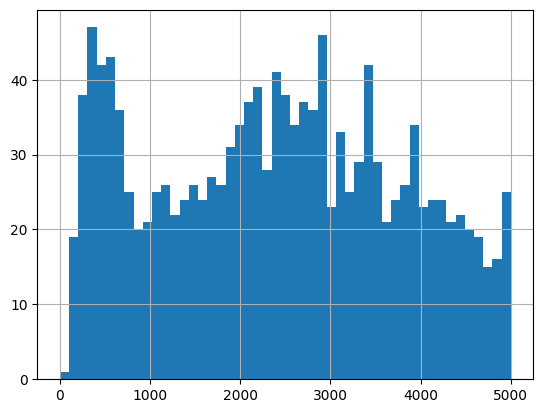

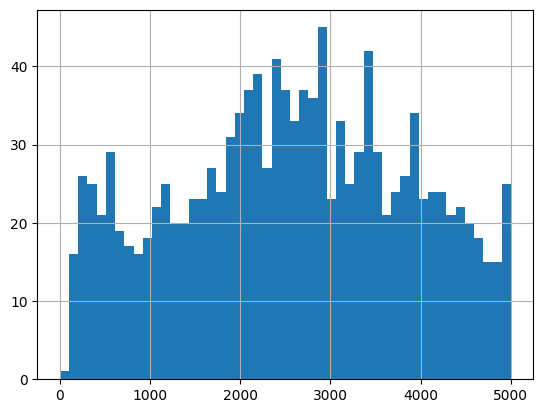

<Axes: >

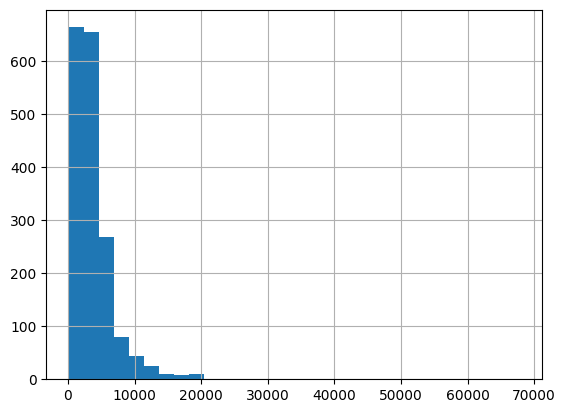

In [42]:
import matplotlib.pyplot as plt
bins = np.linspace(0, 5000, 50)
retail_landuse[retail_landuse["matched_to_centre_ratio"]>0.01]["area_per_total_poi_sqm"].hist(bins=bins)
plt.show()

retail_landuse[retail_landuse["matched_to_centre_ratio"]>0.02]["area_per_total_poi_sqm"].hist(bins=bins)
plt.show()

retail_landuse[retail_landuse["matched_to_centre_ratio"]>0.01]["area_per_total_poi_sqm"].hist(bins=30)